<a href="https://colab.research.google.com/github/adithyaba07/AEC_STATISTICS_LAB/blob/main/STATISTICS3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NORMAL DISTRIBUTION  N(μ, σ²)

Normal Distribution Properties:

  N(μ=0, σ=1):
  Mean=0.00, Var=1.00, Skew=0.00, Kurt=0.00

  N(μ=2, σ=1):
  Mean=2.00, Var=1.00, Skew=0.00, Kurt=0.00

  N(μ=0, σ=2):
  Mean=0.00, Var=4.00, Skew=0.00, Kurt=0.00

  N(μ=-2, σ=0.5):
  Mean=-2.00, Var=0.25, Skew=0.00, Kurt=0.00

68-95-99.7 Rule Verification:
  P(-1 < Z < 1)  = 0.682689 ≈ 68.27%
  P(-2 < Z < 2)  = 0.954500 ≈ 95.45%
  P(-3 < Z < 3)  = 0.997300 ≈ 99.73%

Z-score Examples:
  Score=60, Z=-1.00, Percentile=15.9%
  Score=70, Z=0.00, Percentile=50.0%
  Score=80, Z=1.00, Percentile=84.1%
  Score=90, Z=2.00, Percentile=97.7%

  ML Context — Weight Initialization:
  Xavier init: W ~ N(0, 2/(n_in + n_out))
  For Dense(784→128): σ = 0.046829

EXPONENTIAL DISTRIBUTION  Exp(λ)

  Exp(λ=0.5): Mean=2.0000, Var=4.0000, Std=2.0000

  Exp(λ=1.0): Mean=1.0000, Var=1.0000, Std=1.0000

  Exp(λ=2.0): Mean=0.5000, Var=0.2500, Std=0.5000

  Exp(λ=3.0): Mean=0.3333, Var=0.1111, Std=0.3333

  Memoryless Property (λ=1.0

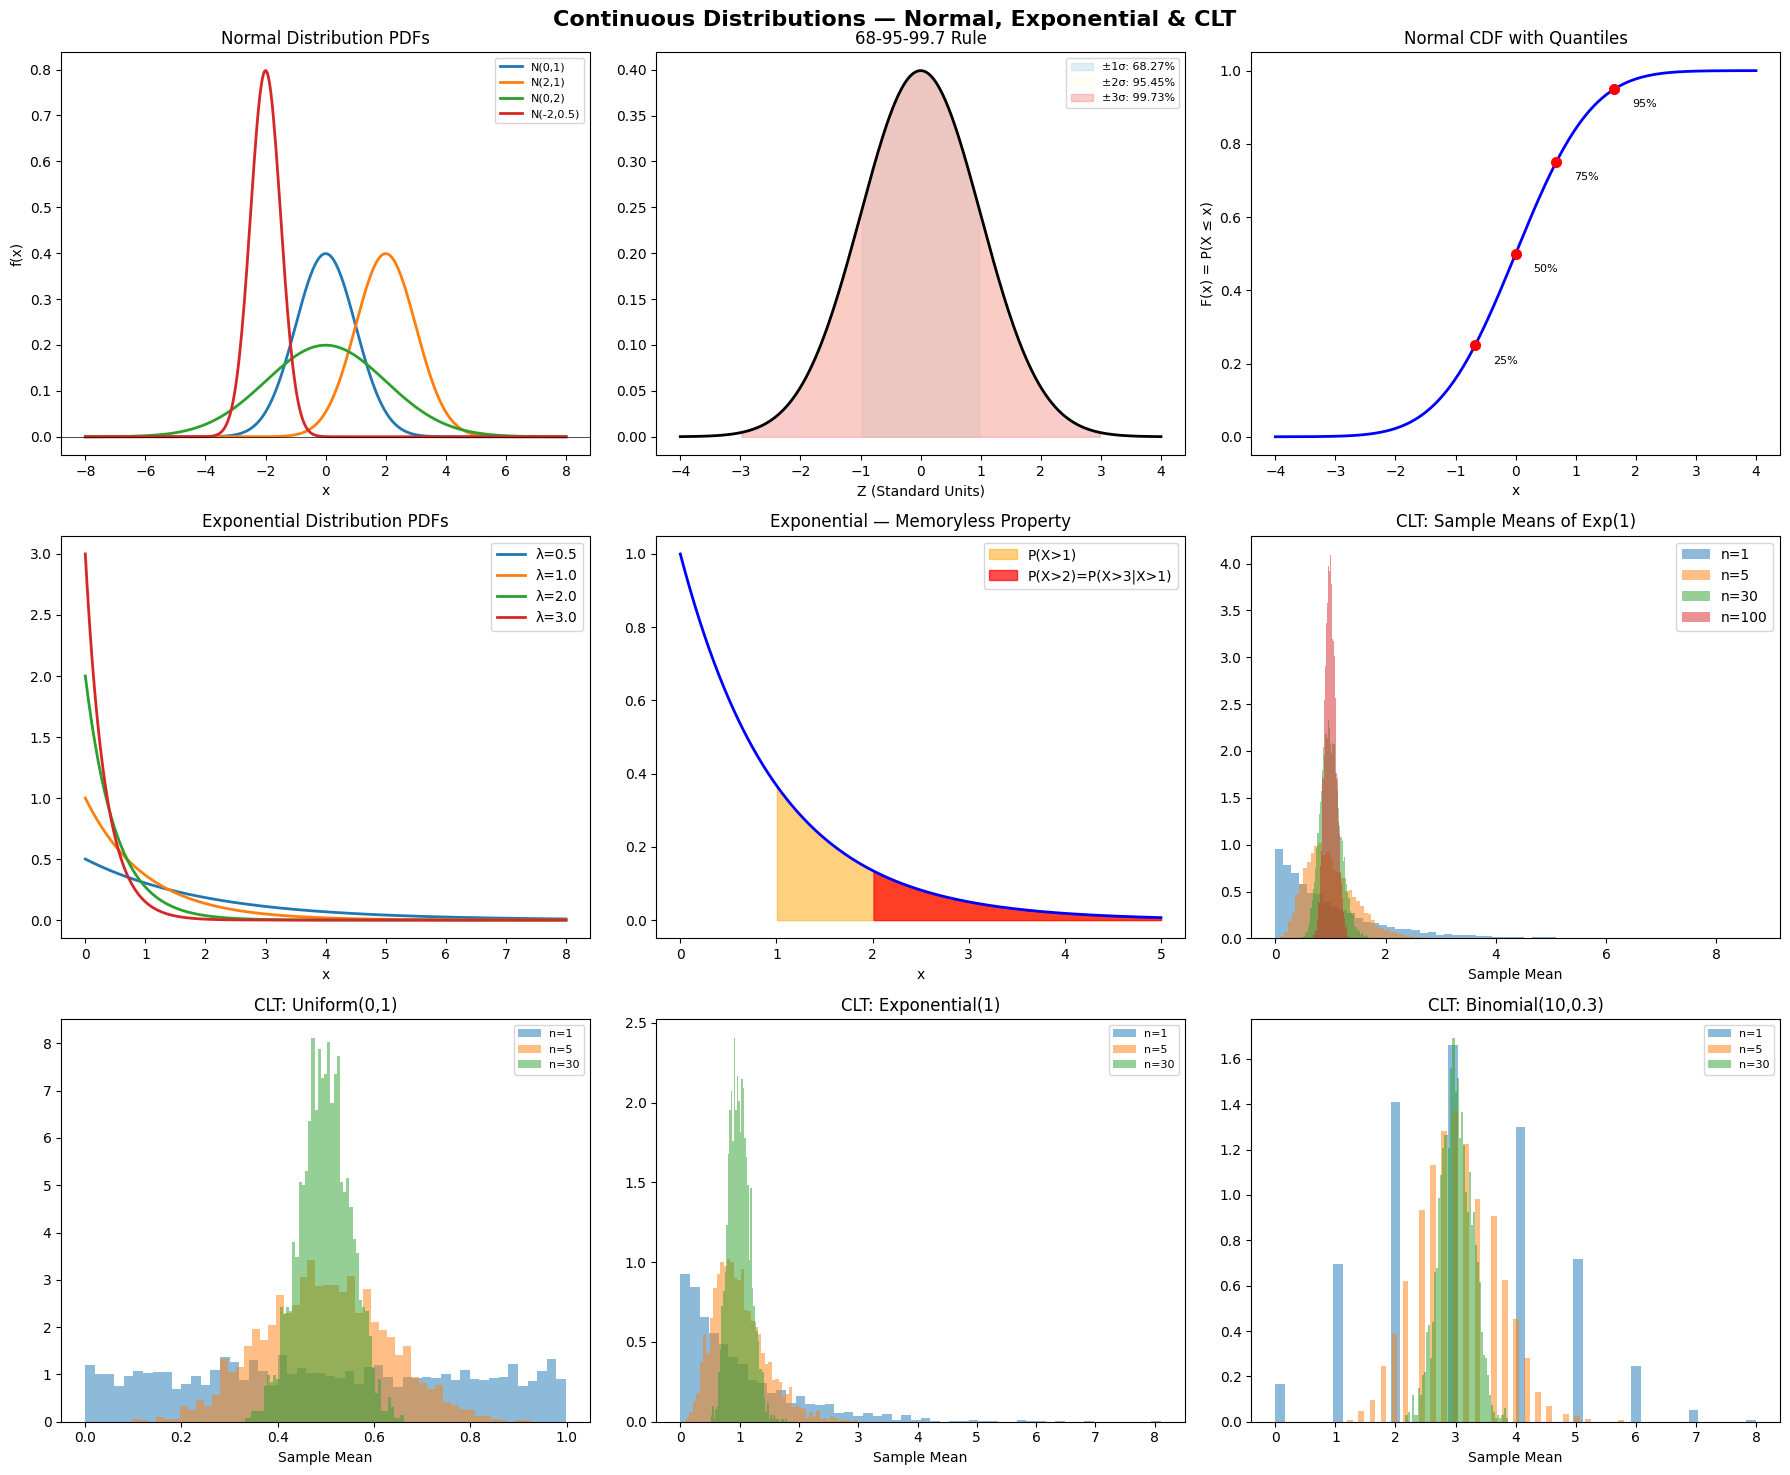


Program 3 Completed Successfully.


In [9]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pandas as pd

np.random.seed(42)

print("=" * 60)
print("NORMAL DISTRIBUTION  N(μ, σ²)")
print("=" * 60)

params = [(0, 1), (2, 1), (0, 2), (-2, 0.5)]
x = np.linspace(-8, 8, 400)

print("\nNormal Distribution Properties:")
for mu, sigma in params:
    dist = stats.norm(mu, sigma)
    print(f"\n  N(μ={mu}, σ={sigma}):")
    print(f"  Mean={dist.mean():.2f}, Var={dist.var():.2f},"
          f" Skew={dist.stats('s'):.2f},"
          f" Kurt={dist.stats('k'):.2f}")

std_normal = stats.norm(0, 1)
print("\n68-95-99.7 Rule Verification:")
print(f"  P(-1 < Z < 1)  = {std_normal.cdf(1) - std_normal.cdf(-1):.6f} ≈ 68.27%")
print(f"  P(-2 < Z < 2)  = {std_normal.cdf(2) - std_normal.cdf(-2):.6f} ≈ 95.45%")
print(f"  P(-3 < Z < 3)  = {std_normal.cdf(3) - std_normal.cdf(-3):.6f} ≈ 99.73%")
print("\nZ-score Examples:")
raw_scores = [60, 70, 80, 90]
mu_exam, sigma_exam = 70, 10
for score in raw_scores:
    z = (score - mu_exam) / sigma_exam
    percentile = std_normal.cdf(z) * 100
    print(f"  Score={score}, Z={z:.2f}, Percentile={percentile:.1f}%")

print("\n  ML Context — Weight Initialization:")
print(f"  Xavier init: W ~ N(0, 2/(n_in + n_out))")
n_in, n_out = 784, 128
xavier_std = np.sqrt(2 / (n_in + n_out))
print(f"  For Dense(784→128): σ = {xavier_std:.6f}")


print("\n" + "=" * 60)
print("EXPONENTIAL DISTRIBUTION  Exp(λ)")
print("=" * 60)

lambdas_exp = [0.5, 1.0, 2.0, 3.0]
x_exp = np.linspace(0, 8, 300)

for lam in lambdas_exp:
    dist_e = stats.expon(scale=1/lam)
    print(f"\n  Exp(λ={lam}): Mean={dist_e.mean():.4f},"
          f" Var={dist_e.var():.4f},"
          f" Std={dist_e.std():.4f}")

lam_main = 1.0
exp_main = stats.expon(scale=1/lam_main)
exp_data = np.random.exponential(1/lam_main, 5000)
print(f"\n  Memoryless Property (λ={lam_main}):")
print(f"  P(X > 2)            = {1 - exp_main.cdf(2):.6f}")
print(f"  P(X > 3 | X > 1)    = {(1 - exp_main.cdf(3)) / (1 - exp_main.cdf(1)):.6f}")
print(f"  Both equal? {abs((1-exp_main.cdf(2)) - (1-exp_main.cdf(3))/(1-exp_main.cdf(1))) < 1e-9}")


print("\n" + "=" * 60)
print("CENTRAL LIMIT THEOREM SIMULATION")
print("=" * 60)

distributions_clt = {
    'Uniform(0,1)': lambda n: np.random.uniform(0, 1, n),
    'Exponential(1)': lambda n: np.random.exponential(1, n),
    'Binomial(10,0.3)': lambda n: np.random.binomial(10, 0.3, n)
}

sample_sizes = [1, 5, 30, 100]
for dist_name, sampler in distributions_clt.items():
    print(f"\n  {dist_name}:")
    for n in sample_sizes:
        sample_means = [np.mean(sampler(n)) for _ in range(2000)]
        print(f"    n={n:>3}: mean={np.mean(sample_means):.4f},"
              f" std={np.std(sample_means):.4f}")


print("\n" + "=" * 60)
print("MOMENTS ANALYSIS")
print("=" * 60)

print("\nRaw Moments E[Xᵏ]:")
dist_norm = stats.norm(0, 1)
for k in range(1, 5):
    raw_moment = dist_norm.moment(k)
    print(f"  E[X^{k}] = {raw_moment:.6f}")

print("\nCentral Moments:")
data_sample = np.random.normal(5, 2, 1000)
for k in range(1, 5):
    central = np.mean((data_sample - np.mean(data_sample))**k)
    print(f"  μ_{k} = {central:.6f}")


fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('Continuous Distributions — Normal, Exponential & CLT',
             fontsize=16, fontweight='bold')


for mu, sigma in params:
    axes[0, 0].plot(x, stats.norm.pdf(x, mu, sigma),
                    linewidth=2, label=f'N({mu},{sigma})')
axes[0, 0].set_title('Normal Distribution PDFs')
axes[0, 0].set_xlabel('x')
axes[0, 0].set_ylabel('f(x)')
axes[0, 0].legend(fontsize=8)
axes[0, 0].axhline(0, color='black', linewidth=0.5)


x_std = np.linspace(-4, 4, 300)
y_std = stats.norm.pdf(x_std)
axes[0, 1].plot(x_std, y_std, 'k-', linewidth=2)
for interval, color, label in [
        (1, 'lightblue', '68.27%'),
        (2, 'lightyellow', '95.45%'),
        (3, 'lightcoral', '99.73%')]:
    axes[0, 1].fill_between(
        x_std, y_std,
        where=(np.abs(x_std) <= interval),
        alpha=0.4, color=color, label=f'±{interval}σ: {label}')
axes[0, 1].set_title('68-95-99.7 Rule')
axes[0, 1].legend(fontsize=8)
axes[0, 1].set_xlabel('Z (Standard Units)')


x_cdf = np.linspace(-4, 4, 300)
axes[0, 2].plot(x_cdf, stats.norm.cdf(x_cdf, 0, 1),
                'blue', linewidth=2)
for q_val in [0.25, 0.50, 0.75, 0.95]:
    q_x = stats.norm.ppf(q_val)
    axes[0, 2].plot(q_x, q_val, 'ro', markersize=7)
    axes[0, 2].annotate(f'{q_val:.0%}',
                        xy=(q_x, q_val),
                        xytext=(q_x+0.3, q_val-0.05),
                        fontsize=8)
axes[0, 2].set_title('Normal CDF with Quantiles')
axes[0, 2].set_xlabel('x')
axes[0, 2].set_ylabel('F(x) = P(X ≤ x)')

for lam in lambdas_exp:
    axes[1, 0].plot(x_exp, stats.expon.pdf(x_exp, scale=1/lam),
                    linewidth=2, label=f'λ={lam}')
axes[1, 0].set_title('Exponential Distribution PDFs')
axes[1, 0].set_xlabel('x')
axes[1, 0].legend()


x_mem = np.linspace(0, 5, 200)
axes[1, 1].fill_between(x_mem, exp_main.pdf(x_mem),
                         where=(x_mem >= 1),
                         alpha=0.5, color='orange',
                         label='P(X>1)')
axes[1, 1].fill_between(x_mem, exp_main.pdf(x_mem),
                         where=(x_mem >= 2),
                         alpha=0.7, color='red',
                         label='P(X>2)=P(X>3|X>1)')
axes[1, 1].plot(x_mem, exp_main.pdf(x_mem), 'b-', linewidth=2)
axes[1, 1].set_title('Exponential — Memoryless Property')
axes[1, 1].legend()
axes[1, 1].set_xlabel('x')


clt_data = np.random.exponential(1, (100, 10000))
for i, n in enumerate([1, 5, 30, 100]):
    means = clt_data[:n, :].mean(axis=0)
    axes[1, 2].hist(means, bins=60, density=True, alpha=0.5,
                    label=f'n={n}')
axes[1, 2].set_title('CLT: Sample Means of Exp(1)')
axes[1, 2].set_xlabel('Sample Mean')
axes[1, 2].legend()


for idx, (dist_name, sampler) in enumerate(
        distributions_clt.items()):
    ax = axes[2, idx]
    for n in [1, 5, 30]:
        sample_means = [np.mean(sampler(n)) for _ in range(2000)]
        ax.hist(sample_means, bins=50, density=True,
                alpha=0.5, label=f'n={n}')
    ax.set_title(f'CLT: {dist_name}')
    ax.set_xlabel('Sample Mean')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('P3_continuous_distributions.png', dpi=150,
            bbox_inches='tight')
plt.show()
print("\nProgram 3 Completed Successfully.")



First 10 generated student marks:
[58.91454325 62.73979399 67.20701986 86.46534976 75.60671578 60.81044029
 81.27085499 72.92330363 75.47407857 60.23332738]

Parameters of the Normal Distribution
-------------------------------------
Mean: 70
Standard deviation: 10
Number of students: 1000

Statistics of Generated Marks
------------------------------
Sample mean: 70.21
Sample standard deviation: 9.78
Minimum mark: 32.87
Maximum mark: 98.99


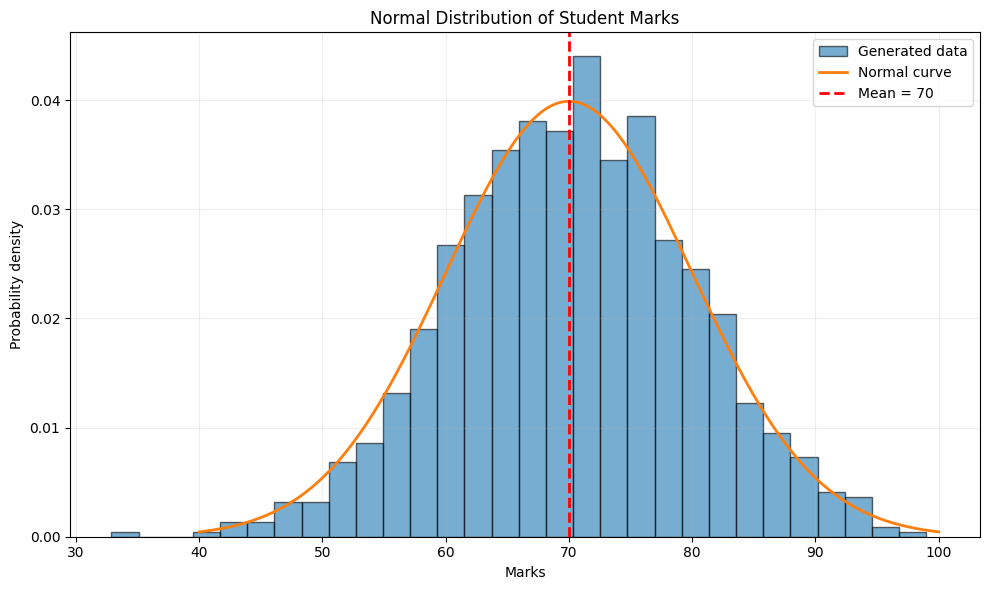


Z-Score Calculation
-------------------
Student mark: 80
Mean: 70
Standard deviation: 10
Z-score for mark 80: 1.0
The mark is above the mean.

Conclusion:
The histogram represents the generated student marks.
The curve represents the theoretical normal distribution.
The z-score shows the distance from the mean in standard deviations.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Step 1: Define the parameters of the normal distribution
mean = 70
std_dev = 10
num_students = 1000

# Step 2: Generate 1000 random student marks
data = np.random.normal(mean, std_dev, num_students)

# Step 3: Display the first 10 generated marks
print("First 10 generated student marks:")
print(data[:10])

# Step 4: Display the parameters
print("\nParameters of the Normal Distribution")
print("-------------------------------------")
print("Mean:", mean)
print("Standard deviation:", std_dev)
print("Number of students:", num_students)

# Step 5: Calculate basic statistics of generated marks
sample_mean = np.mean(data)
sample_std_dev = np.std(data)
minimum_mark = np.min(data)
maximum_mark = np.max(data)

# Step 6: Display the calculated statistics
print("\nStatistics of Generated Marks")
print("------------------------------")
print("Sample mean:", round(sample_mean, 2))
print("Sample standard deviation:", round(sample_std_dev, 2))
print("Minimum mark:", round(minimum_mark, 2))
print("Maximum mark:", round(maximum_mark, 2))

# Step 7: Create a figure for plotting
plt.figure(figsize=(10, 6))

# Step 8: Plot the histogram of generated marks
plt.hist(
    data,
    bins=30,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Generated data"
)

# Step 9: Generate values for the theoretical normal curve
x = np.linspace(40, 100, 200)

# Step 10: Calculate probability density values
y = norm.pdf(x, mean, std_dev)

# Step 11: Plot the theoretical normal distribution curve
plt.plot(
    x,
    y,
    linewidth=2,
    label="Normal curve"
)

# Step 12: Mark the mean on the graph
plt.axvline(
    mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Mean = 70"
)

# Step 13: Add labels to the horizontal and vertical axes
plt.xlabel("Marks")
plt.ylabel("Probability density")

# Step 14: Add a title to the graph
plt.title("Normal Distribution of Student Marks")

# Step 15: Display the legend
plt.legend()

# Step 16: Add a light grid for better readability
plt.grid(alpha=0.2)

# Step 17: Adjust the graph layout
plt.tight_layout()

# Step 18: Display the completed graph
plt.show()

# Step 19: Select the student mark for z-score calculation
mark = 80

# Step 20: Calculate the z-score
z_score = (mark - mean) / std_dev

# Step 21: Display the z-score calculation
print("\nZ-Score Calculation")
print("-------------------")
print("Student mark:", mark)
print("Mean:", mean)
print("Standard deviation:", std_dev)
print("Z-score for mark 80:", z_score)

# Step 22: Interpret the z-score
if z_score > 0:
    print("The mark is above the mean.")
elif z_score < 0:
    print("The mark is below the mean.")
else:
    print("The mark is equal to the mean.")

# Step 23: Display the final conclusion
print("\nConclusion:")
print("The histogram represents the generated student marks.")
print("The curve represents the theoretical normal distribution.")
print("The z-score shows the distance from the mean in standard deviations.")

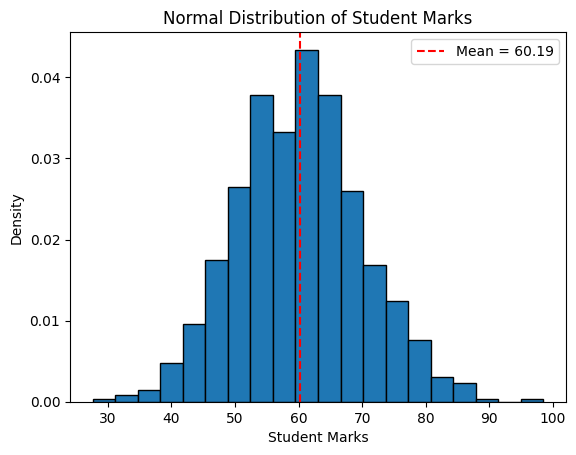

Average marks: 60.19


In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Marks of 1000 students
np.random.seed(42)
marks = np.random.normal(60, 10, 1000)

# Calculate mean
mean = np.mean(marks)

# Draw graph
plt.hist(marks, bins=20, density=True, edgecolor="black")
plt.axvline(mean, color="red", linestyle="--",
            label=f"Mean = {mean:.2f}")

plt.title("Normal Distribution of Student Marks")
plt.xlabel("Student Marks")
plt.ylabel("Density")
plt.legend()
plt.show()

print("Average marks:", round(mean, 2))